# Лабораторна робота №2
## Baseline Classification Pipeline

### Мета роботи:
відтворити базовий життєвий цикл машинного навчання для задачі класифікації: підготувати дані, розділити їх на навчальну та валідаційну вибірки, навчити модель, оцінити її якість та сформувати прогноз для тестових даних.


1. Підключення бібліотек і завантаження даних

In [1]:
import pandas as pd

train = pd.read_csv("application_train.csv")
test = pd.read_csv("application_test.csv")

In [2]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (307511, 122)
Test shape: (48744, 121)


In [3]:
train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


2. Відокремлення цільової змінної

In [4]:
X = train.drop(columns=["TARGET"])
y = train["TARGET"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (307511, 121)
y shape: (307511,)


3. Аналіз типів даних та пропущених значень

In [5]:
print(X.dtypes.value_counts())

float64    65
int64      40
str        16
Name: count, dtype: int64


In [6]:
missing = X.isnull().sum()

print("Кількість колонок із пропусками:", (missing > 0).sum())
print("Загальна кількість пропущених значень:", missing.sum())

Кількість колонок із пропусками: 67
Загальна кількість пропущених значень: 9152465


In [7]:
missing[missing > 0].sort_values(ascending=False).head(10)

COMMONAREA_MEDI             214865
COMMONAREA_MODE             214865
COMMONAREA_AVG              214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
dtype: int64

4. Розділення даних на навчальну та валідаційну вибірки

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Навчальна вибірка:", X_train.shape)
print("Валідаційна вибірка:", X_val.shape)

Навчальна вибірка: (246008, 121)
Валідаційна вибірка: (61503, 121)


5. Визначення числових і категоріальних ознак

In [9]:
numeric_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_cols = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns

print("Числових ознак:", len(numeric_cols))
print("Категоріальних ознак:", len(categorical_cols))

Числових ознак: 105
Категоріальних ознак: 16


6. Обробка пропущених значень

In [10]:
from sklearn.impute import SimpleImputer

numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train[numeric_cols] = numeric_imputer.fit_transform(
    X_train[numeric_cols]
)

X_val[numeric_cols] = numeric_imputer.transform(
    X_val[numeric_cols]
)

X_train[categorical_cols] = categorical_imputer.fit_transform(
    X_train[categorical_cols]
)

X_val[categorical_cols] = categorical_imputer.transform(
    X_val[categorical_cols]
)

In [11]:
print("Пропусків у X_train:", X_train.isnull().sum().sum())
print("Пропусків у X_val:", X_val.isnull().sum().sum())

Пропусків у X_train: 0
Пропусків у X_val: 0


7. Кодування категоріальних ознак

In [12]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_encoded = encoder.fit_transform(
    X_train[categorical_cols]
)

X_val_encoded = encoder.transform(
    X_val[categorical_cols]
)

8. Формування підготовлених вибірок

In [13]:
encoded_cols = encoder.get_feature_names_out(categorical_cols)

X_train_cat = pd.DataFrame(
    X_train_encoded,
    columns=encoded_cols,
    index=X_train.index
)

X_val_cat = pd.DataFrame(
    X_val_encoded,
    columns=encoded_cols,
    index=X_val.index
)

X_train_final = pd.concat(
    [X_train[numeric_cols], X_train_cat],
    axis=1
)

X_val_final = pd.concat(
    [X_val[numeric_cols], X_val_cat],
    axis=1
)

In [14]:
print("Навчальна вибірка:", X_train_final.shape)
print("Валідаційна вибірка:", X_val_final.shape)

print("Текстових колонок:",
      X_train_final.select_dtypes(include=["object", "str"]).shape[1])

print("Пропущених значень:",
      X_train_final.isnull().sum().sum())

Навчальна вибірка: (246008, 245)
Валідаційна вибірка: (61503, 245)
Текстових колонок: 0
Пропущених значень: 0


9. Навчання моделі дерева рішень

In [15]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier()

model.fit(X_train_final, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

10. Прогнозування на валідаційній вибірці

In [16]:
y_val_pred = model.predict(X_val_final)
y_val_proba = model.predict_proba(X_val_final)[:, 1]

11. Оцінювання моделі за метрикою ROC-AUC

In [17]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_val, y_val_proba)

print(f"ROC-AUC: {roc_auc:.4f}")

ROC-AUC: 0.5366


12. Побудова матриці помилок

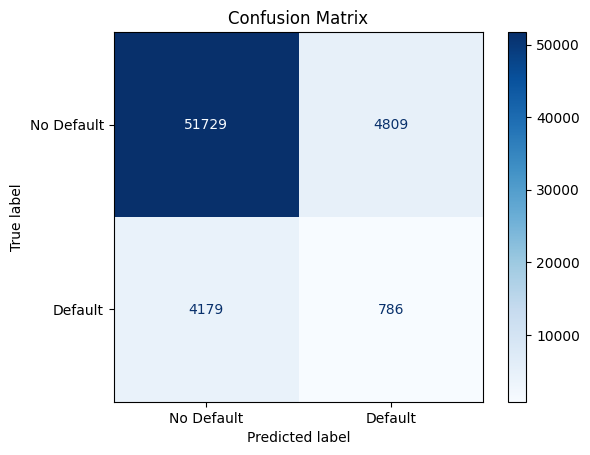

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Default", "Default"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

13. Обчислення додаткових метрик класифікації

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_val, y_val_pred)
precision = precision_score(y_val, y_val_pred)
recall = recall_score(y_val, y_val_pred)
f1 = f1_score(y_val, y_val_pred)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

Accuracy:  0.8539
Precision: 0.1405
Recall:    0.1583
F1-score:  0.1489


14. Аналіз результатів класифікації
    
За результатами оцінювання модель досягла ROC-AUC = 0.5366 та Accuracy = 0.8539. Попри високу загальну точність, значення Precision (0.1405), Recall (0.1583) та F1-score (0.1489) свідчать про низьку ефективність виявлення клієнтів із ризиком дефолту.

Матриця помилок показала, що модель правильно класифікувала 51 729 клієнтів без дефолту та 786 клієнтів із дефолтом. Водночас було отримано 4 809 хибнопозитивних і 4 179 хибнонегативних прогнозів.

Отримані результати свідчать, що модель краще класифікує клієнтів без дефолту. Можливими причинами є дисбаланс класів і перенавчання дерева рішень.

15. Обробка пропущених значень у тестових даних

In [20]:
test[numeric_cols] = numeric_imputer.transform(
    test[numeric_cols]
)

test[categorical_cols] = categorical_imputer.transform(
    test[categorical_cols]
)

16. Кодування категоріальних ознак тестових даних

In [21]:
test_encoded = encoder.transform(
    test[categorical_cols]
)

test_cat = pd.DataFrame(
    test_encoded,
    columns=encoded_cols,
    index=test.index
)

test_final = pd.concat(
    [test[numeric_cols], test_cat],
    axis=1
)

test_final = test_final[X_train_final.columns]

In [22]:
print("Test shape:", test_final.shape)
print("Missing values:", test_final.isnull().sum().sum())

Test shape: (48744, 245)
Missing values: 0


17. Прогнозування ймовірності дефолту

In [23]:
test_proba = model.predict_proba(test_final)[:, 1]

In [24]:
submission = pd.DataFrame({
    "SK_ID_CURR": test["SK_ID_CURR"],
    "TARGET": test_proba
})

submission.head()

,SK_ID_CURR,TARGET
0,100001.0,0.0
1,100005.0,0.0
2,100013.0,0.0
3,100028.0,0.0
4,100038.0,0.0


In [25]:
submission.to_csv("submission.csv", index=False)

In [26]:
print(submission.shape)
print(submission.isnull().sum())

(48744, 2)
SK_ID_CURR    0
TARGET        0
dtype: int64


18. Перевірка результатів прогнозування

In [27]:
submission["SK_ID_CURR"] = submission["SK_ID_CURR"].astype(int)

print(submission["TARGET"].describe())
print(submission["TARGET"].value_counts().head())

submission.to_csv("submission.csv", index=False)

count    48744.000000
mean         0.093365
std          0.290947
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: TARGET, dtype: float64
TARGET
0.0    44193
1.0     4551
Name: count, dtype: int64


19. Оцінювання моделі на платформі Kaggle

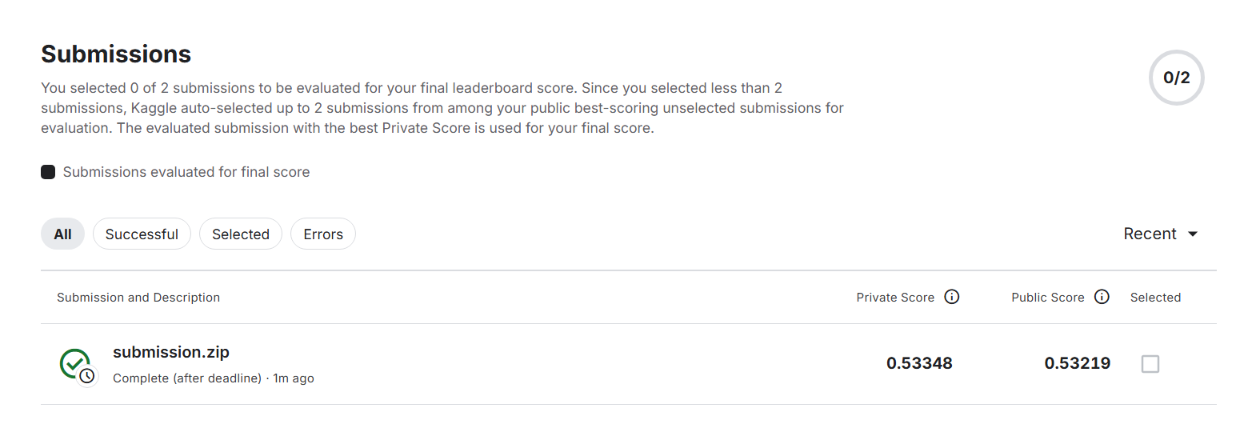

**Рисунок 1 – Результати оцінювання моделі на платформі Kaggle**

Після формування та завантаження файлу submission.zip на платформу Kaggle було отримано оцінки Public Score = 0.53219 та Private Score = 0.53348. Отримані результати близькі до значення ROC-AUC = 0.5366 на валідаційній вибірці, що свідчить про узгодженість результатів оцінювання моделі.

### Висновок

У ході лабораторної роботи було реалізовано базовий процес машинного навчання для задачі класифікації. Проведено підготовку даних, обробку пропущених значень, кодування категоріальних ознак та навчання моделі Decision Tree Classifier. Якість моделі оцінено за допомогою ROC-AUC, матриці помилок та додаткових метрик класифікації.

Отримані результати показали, що модель краще визначає клієнтів без дефолту, проте має низьку ефективність виявлення ризикових клієнтів. Також було сформовано прогноз для тестових даних та успішно завантажено його на платформу Kaggle.